# 같은 평가셋으로 RAG 비교

**이 노트북에서 할 일**

1. Ch 14 질문 셋을 고정 흐름과 에이전트 흐름에 똑같이 보냅니다.
2. 두 흐름의 모델 요청 수·도구 메시지 수·입력 토큰·정답 문서 자리를 코드로 셉니다.
3. Ch 15 평가 모델로 답을 판정하고, Ch 29 04절이 읽을 비교 기록 파일을 씁니다.

**준비물** — 프로젝트 폴더의 `.env` 파일에 `OPENAI_API_KEY`가 있어야 합니다.
모델은 `gpt-5.4-mini`이고, 교재 출력에서 모델 요청은 모두 15번입니다.
고정 흐름 3번, 에이전트 흐름 6번, 평가 모델 판정 6번입니다.
임베딩 모델은 `text-embedding-3-small`이고, 임베딩 요청은 모두 7번입니다.

에이전트가 검색 도구를 부르는 횟수가 달라지면, 모델 요청 수와 임베딩 요청 수가 함께 달라집니다.
요금표로 어림한 예상 비용은 모두 합쳐 0.01달러 아래이고, 청구 금액이 아닙니다.
이 어림에 임베딩 요금은 넣지 않았고, 수백 토큰이라 아주 작습니다.

읽는 파일은 Ch 14 실습 폴더의 `documents.json`과 `queries.json` 둘이고, 읽기만 합니다.
쓰는 파일은 이 실습 폴더의 `data/rag-comparison.json` 하나이고, Ch 29 04절이 이 파일을 읽습니다.
다시 실행하면 같은 파일을 덮어쓰므로, 값이 바뀌면 Ch 29 04절 출력도 따라 바뀝니다.

앞에서 배운 함수 여덟은 도구 파일 `runner_tools.py`에서 가져옵니다.
교재 출력을 만든 실행에서는 노트북 전체가 20초 안에 끝났습니다.
모델과 임베딩 응답을 기다리는 시간은 네트워크와 실행 때에 따라 달라집니다.

**기준 버전** — 첫 셀에서 패키지 여섯을 설치합니다.
판은 langchain 1.4.0, langchain-core 1.6.2, langchain-openai 1.6.0입니다.
langgraph 1.2.11, numpy 2.5.3, python-dotenv 1.2.3도 함께 설치합니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 이번에 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 3~6절을 읽습니다.
자료와 검색 도구를 준비하고, 두 흐름을 만들어 질문 셋을 한 번씩 보내는 자리입니다.
7~11절은 결과를 세고 판정하고 파일을 쓰는 자리이고, 실습 시간에 실행합니다.

실습 폴더 `labs/part6/ch21-create-agent`에서 `uv sync --locked`를 실행합니다.
그다음 `notebooks/` 폴더의 이 노트북을 열고, 실습 폴더의 `.venv` 커널을 고릅니다.
첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![맨 위 초록 상자 같은 질문 셋 C01 C05 C07에서 칸 둘로 화살표가 갑니다. 왼쪽 칸 고정 흐름 코드가 먼저 검색에는 파란 상자 코드가 질문 글로 검색 도구를 부름, 파란 상자 요청 글 하나 답 머리글 질문 문서 세 줄, 보라 상자 모델 요청 한 번이 위에서 아래로 이어집니다. 오른쪽 칸 에이전트 흐름 모델이 검색을 부름에는 보라 상자 첫 모델 요청 도구 호출 요청, 회색 상자 도구 실행 노드가 검색 도구를 부름, 보라 상자 둘째 모델 요청 도구 메시지를 보고 답이 이어집니다. 맨 아래 회색 상자에 두 흐름 공통 검색 도구 search_documents 문서 벡터 열두 개 자를 개수 셋 모델 gpt-5.4-mini가 적힌 그림](attachment:06-1-같은-도구를-쓰는-두-흐름.png)

맨 위 초록 상자는 두 흐름에 똑같이 보낸 질문 셋입니다.
왼쪽 칸은 고정 흐름으로, 파란 상자 둘은 우리가 적은 코드이고 보라 상자는 실제로 부른 모델입니다.
오른쪽 칸은 에이전트 흐름으로, 모델 요청 두 번 사이에 회색 도구 실행 노드가 검색 도구를 부릅니다.
맨 아래 회색 상자는 두 흐름에 같았던 조건입니다.
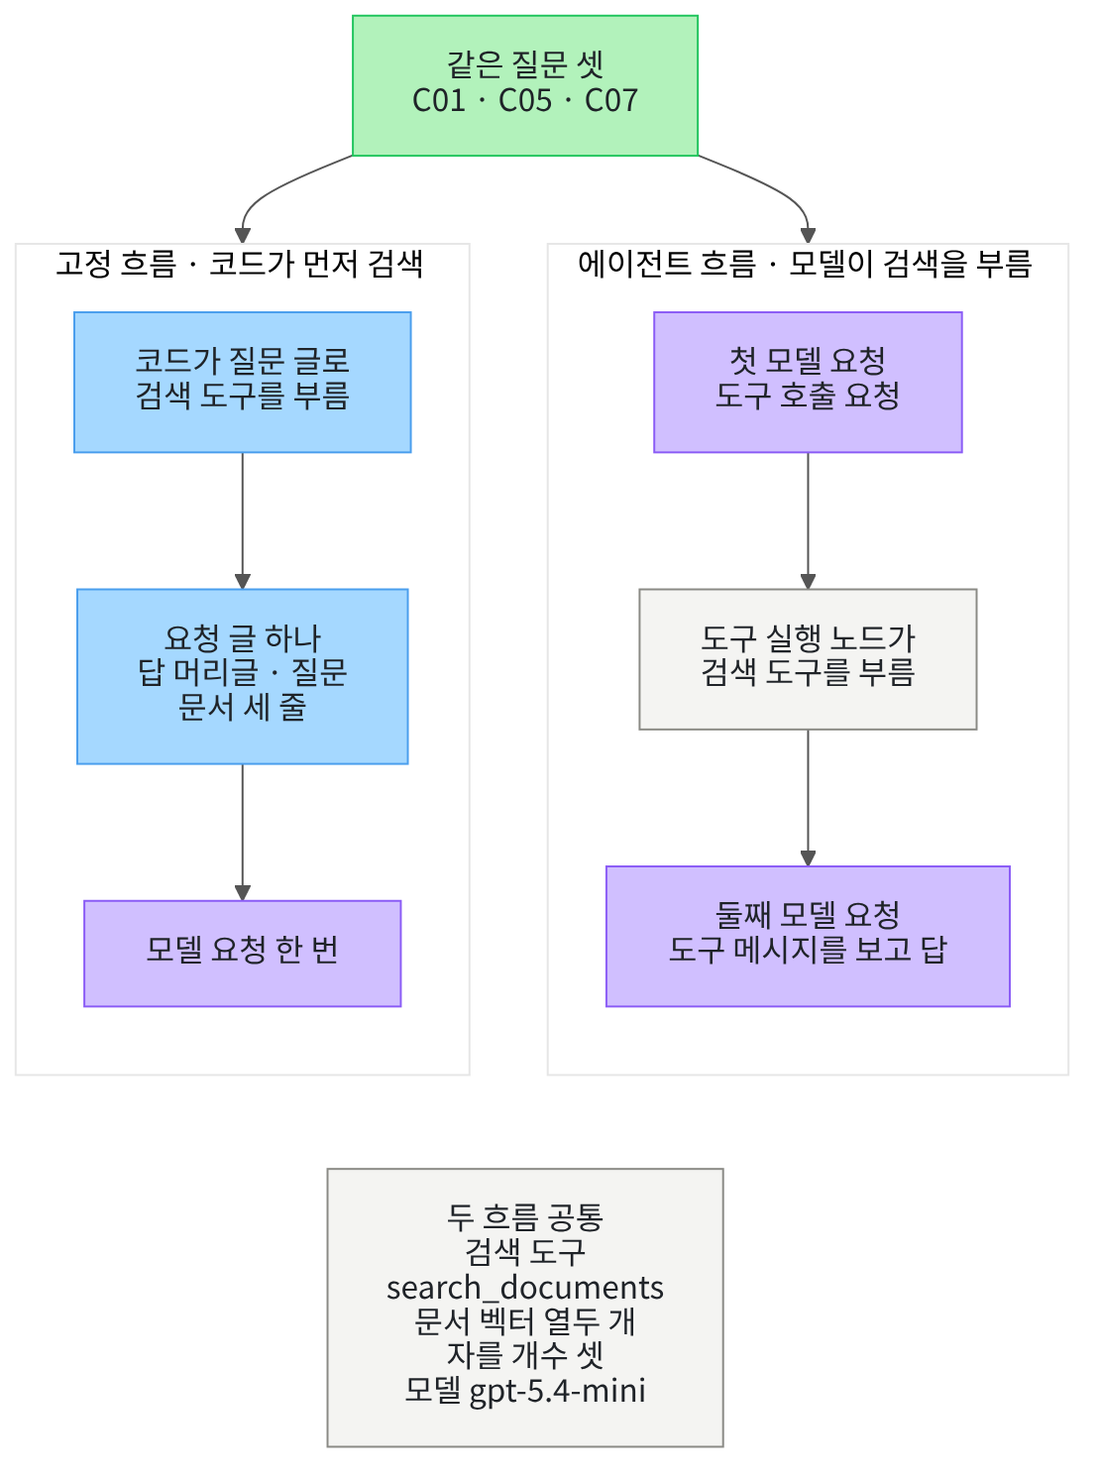

## 1. 준비

05절에서는 검색 함수를 도구로 감싸 에이전트 그래프에 넣었습니다.
이 절에서는 같은 질문 셋을 두 흐름으로 보내 견줍니다.
하나는 코드가 늘 먼저 검색하고 모델에 한 번 묻는 고정 흐름입니다.
다른 하나는 05절 검색 도구를 모델이 부르는 에이전트 흐름입니다.

첫 셀은 패키지 여섯 개를 설치하고 설치된 판 번호를 출력합니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain==1.4.0" "langchain-core==1.6.2" "langchain-openai==1.6.0" "langgraph==1.2.11" "numpy==2.5.3" "python-dotenv==1.2.3"
from importlib.metadata import version

print("langchain:", version("langchain"))
print("langchain-core:", version("langchain-core"))
print("langchain-openai:", version("langchain-openai"))
print("langgraph:", version("langgraph"))
print("numpy:", version("numpy"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.


langchain: 1.4.0
langchain-core: 1.6.2
langchain-openai: 1.6.0
langgraph: 1.2.11
numpy: 2.5.3
python-dotenv: 1.2.3


**결과 읽기** — 출력 줄 `langchain: 1.4.0`·`langchain-core: 1.6.2`·`langchain-openai: 1.6.0`이 보입니다.
출력 줄 `langgraph: 1.2.11`·`numpy: 2.5.3`·`python-dotenv: 1.2.3`도 잠금과 같은 판입니다.
이 노트북의 출력은 2026-09-25에 이 판으로 실행한 결과입니다.

다음 셀은 이 절에서 쓸 이름을 가져옵니다.
모듈 `time`은 Ch 15 05절에서 걸린 시간을 잴 때 썼습니다.
나머지 라이브러리 이름은 05절과 같습니다.

In [2]:
# 문서 파일을 읽을 이름, 시각을 잴 이름, 임베딩 모델, 에이전트와 도구를 만드는 이름을 가져옵니다
import json
import os
import time

from langchain.agents import create_agent
from langchain.chat_models import init_chat_model
from langchain.messages import HumanMessage
from langchain.tools import tool
from langchain_openai import OpenAIEmbeddings

# 앞에서 배운 함수는 도구 파일에서 가져옵니다(find_gold_rank·build_judge_prompt·judge_once는 이 절부터 가져옵니다)
from runner_tools import agent_row, build_judge_prompt, estimate_cost, find_gold_rank
from runner_tools import judge_once, search_hits, show_messages, sum_usage

print("이 절에서 처음 가져온 이름:", "time", "find_gold_rank", "build_judge_prompt", "judge_once")

이 절에서 처음 가져온 이름: time find_gold_rank build_judge_prompt judge_once


**결과 읽기** — 출력 줄 `이 절에서 처음 가져온 이름: time find_gold_rank build_judge_prompt judge_once`가 보입니다.
앞 챕터에서 쓴 이름이지만, 이 챕터에서는 처음 가져옵니다.

앞에서 배운 함수는 `runner_tools.py`에 모아 두었습니다. 파일을 열면 코드를 볼 수 있습니다. 노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다. 커널이 `notebooks/` 폴더에서 시작해야 이 파일을 가져올 수 있습니다.

함수 `find_gold_rank`는 Ch 11 01절에서 배웠습니다.
함수 `build_judge_prompt`와 `judge_once`는 Ch 15 02절에서 배웠습니다.
세 함수는 Ch 15 도구 파일에서 본문을 글자 그대로 옮겼고, 인자 모양도 Ch 15와 같습니다.
나머지 다섯 이름은 01·05절처럼 이 도구 파일에서 가져옵니다.

## 2. 키와 모델 준비

모델은 01절과 같은 `gpt-5.4-mini`이고, 과정의 같은 설정으로 부릅니다.
이 모델 객체를 두 흐름과 평가 모델 판정에 함께 씁니다.

API 키가 있는지 확인합니다. `True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


실습에 쓸 모델을 준비합니다.
temperature 값을 0으로 두어도, 모델이 쓰는 답 글과 검색어가 매번 같다고 보장하지는 않습니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 모델 이름 `gpt-5.4-mini`, temperature `0.0`이 보이면 준비가 끝났습니다.
이 노트북의 출력은 2026-09-25에 이 모델로 실행한 결과입니다.

## 3. Ch 14 문서와 평가 질문

05절처럼 Ch 14 실습 폴더의 문서 열두 건과 질문 여덟 건을 씁니다.
두 파일이 Ch 14 폴더에 있으므로, 다음 셀은 먼저 프로젝트 맨 위 폴더를 찾습니다.
다음 셀은 05절 셀과 글자까지 같은 코드입니다.

In [5]:
# 노트북을 어느 폴더에서 열어도 프로젝트 맨 위를 찾게 후보 세 개를 차례로 봅니다
candidates = [".", "../../..", "../../../.."]
root_path = None
for candidate in candidates:
    if os.path.exists(candidate + "/labs/part4/ch14-rag-patterns/data"):
        root_path = candidate
        break
print("고른 자리:", root_path)
assert root_path is not None, "notebooks 폴더나 실습 폴더 맨 위에서 노트북을 열어 주세요."

고른 자리: .


**결과 읽기** — 출력 줄 `고른 자리: .`은 교재 출력을 프로젝트 맨 위에서 실행했다는 뜻입니다.
교재 출력은 실행 도구에 도구 파일 폴더를 따로 알려 준 실행이라 `.`이 찍혔습니다.
노트북을 `notebooks/` 폴더에서 열면 이 줄에 `../../../..`가 찍힙니다.
10절에서 비교 기록 파일을 쓸 때도 이 자리를 씁니다.

다음 셀은 두 파일을 읽습니다.
코드는 05절 셀과 글자까지 같습니다.

In [6]:
# Ch 14 폴더의 문서 파일과 질문 파일을 읽습니다(읽기만 하고 고치지 않습니다)
data_path = root_path + "/labs/part4/ch14-rag-patterns/data"
with open(data_path + "/documents.json", encoding="utf-8") as file:
    docs = json.loads(file.read())
with open(data_path + "/queries.json", encoding="utf-8") as file:
    queries = json.loads(file.read())
print("문서 수:", len(docs))
print("질문 수:", len(queries))

문서 수: 12
질문 수: 8


**결과 읽기** — 출력 줄 `문서 수: 12`와 `질문 수: 8`로, 05절과 같은 자료입니다.
두 파일은 Ch 14 실습 폴더의 파일이라, 이 노트북은 읽기만 합니다.

다음 셀도 05절과 같은 코드로, 문서마다 제목과 본문을 빈칸 하나로 이어 붙입니다.
문서 ID로 그 글을 찾는 딕셔너리 `text_by_doc`도 함께 만듭니다.

In [7]:
# 문서 12건의 제목과 본문을 이어 붙이고, 문서 ID 목록과 문서 ID로 글을 찾는 딕셔너리를 만듭니다
doc_texts = []
doc_ids = []
text_by_doc = {}
for doc in docs:
    # Ch 12·14와 같은 「제목 + 빈칸 + 본문」 모양입니다
    doc_text = doc["title"] + " " + doc["text"]
    doc_texts.append(doc_text)
    doc_ids.append(doc["doc_id"])
    text_by_doc[doc["doc_id"]] = doc_text
print("문서 ID 목록:")
print(doc_ids)

문서 ID 목록:
['LIB-001', 'LIB-002', 'LIB-003', 'LIB-004', 'FAC-001', 'FAC-002', 'FAC-003', 'FAC-004', 'ACC-001', 'ACC-002', 'ACC-003', 'ACC-004']


**결과 읽기** — 라벨 줄 `문서 ID 목록:` 아래에 `LIB-001`부터 `ACC-004`까지 열두 개가 보입니다.
05절 출력과 같은 차례입니다.

다음 셀은 질문 파일에서 `C01`·`C05`·`C07` 세 질문을 고릅니다.
질문마다 적힌 정답 문서 ID(Ch 11 01절 말)도 함께 봅니다.
두 흐름에 보낼 평가 질문 셋입니다.

In [8]:
# 질문 파일에서 C01·C05·C07 세 질문을 고릅니다(질문마다 정답 문서 ID가 함께 있습니다)
picked_qids = ["C01", "C05", "C07"]
eval_cases = []
for query in queries:
    if query["qid"] in picked_qids:
        eval_cases.append(query)
print("평가 질문 수:", len(eval_cases))
for case in eval_cases:
    print(case["qid"], "|", case["question"], "| 정답 문서 ID:", case["gold_doc_id"])

평가 질문 수: 3
C01 | 책을 빌릴 수 있는 기간은 며칠인가요? | 정답 문서 ID: LIB-001
C05 | 토요일 자료실 폐관 시각은? | 정답 문서 ID: FAC-003
C07 | 휴학 중 원격 전자자료를 볼 수 있나요? | 정답 문서 ID: ACC-002


**결과 읽기** — 출력 줄 `평가 질문 수: 3` 아래에 질문 셋이 한 줄씩 보입니다.
정답 문서 ID는 `C01`이 `LIB-001`, `C05`가 `FAC-003`, `C07`이 `ACC-002`입니다.
이 질문 셋을 두 흐름에 똑같이 보내 견주는 것이 Ch 18 06절의 같은 조건 비교입니다.

## 4. 문서 벡터와 같은 검색 도구

다음 셀은 05절과 같은 임베딩 모델과 벡터 크기로 문서 열두 건을 벡터로 바꿉니다.
코드는 05절 셀과 글자까지 같고, 이 셀의 임베딩 요청은 1번입니다.

In [9]:
# Ch 14 06절과 같은 임베딩 모델과 벡터 크기로 문서 12건을 벡터로 바꿉니다(임베딩 요청 1번)
embedding_model_name = "text-embedding-3-small"
vector_dimensions = 256
embedding_model = OpenAIEmbeddings(model=embedding_model_name, dimensions=vector_dimensions)
doc_vectors = embedding_model.embed_documents(doc_texts)
print("임베딩 모델 이름:", embedding_model.model)
print("벡터의 숫자 개수 설정:", embedding_model.dimensions)
print("문서 벡터 수:", len(doc_vectors))

임베딩 모델 이름: text-embedding-3-small
벡터의 숫자 개수 설정: 256
문서 벡터 수: 12


**결과 읽기** — 출력 줄 `임베딩 모델 이름: text-embedding-3-small`과 `벡터의 숫자 개수 설정: 256`입니다.
출력 줄 `문서 벡터 수: 12`로, 05절과 같은 설정의 문서 벡터가 생겼습니다.

다음 셀은 두 흐름에 같게 둘 값 둘을 적습니다.
자를 개수 `top_count`는 05절과 같은 3이고, 검색 도구가 이 값을 읽습니다.
답 머리글 `answer_head`는 고정 흐름이 요청 글 맨 앞에 붙일 글입니다.
05절 시스템 메시지 글에서 도구 이름과 다시 검색 규칙만 뺀 글입니다.

In [10]:
# 두 흐름에 같게 둘 자를 개수와, 고정 흐름이 요청 글 맨 앞에 붙일 답 머리글을 적습니다
top_count = 3
answer_head = "교육센터 자료실 안내 도우미입니다. 자료실 이용을 묻는 질문에는 아래 자료의 문서 글에 근거해 답하세요. "
answer_head = answer_head + "자료에 답이 없으면 문서에서 찾지 못했다고 답하세요.\n\n"
print("자를 개수:", top_count)
print("답 머리글:")
print(answer_head)

자를 개수: 3
답 머리글:
교육센터 자료실 안내 도우미입니다. 자료실 이용을 묻는 질문에는 아래 자료의 문서 글에 근거해 답하세요. 자료에 답이 없으면 문서에서 찾지 못했다고 답하세요.




**결과 읽기** — 출력 줄 `자를 개수: 3`입니다.
라벨 줄 `답 머리글:` 아래 두 문장이 고정 흐름의 규칙 글입니다.
첫 문장은 05절 시스템 메시지 글의 첫 문장과 같습니다.

다음 셀은 05절 검색 도구 셀과 글자까지 같은 코드입니다.
두 흐름 모두 이 도구 하나로 검색하므로, 모델이 받는 문서 글의 모양이 같습니다.
부를 때마다 몸통의 `search_hits`가 임베딩 요청을 1번 보냅니다.

In [11]:
# 검색 함수 search_hits를 도구로 감쌉니다(맨 @tool 줄 — Ch 19 01절, 부를 때마다 임베딩 요청 1번)
@tool
def search_documents(query: str):
    """교육센터 자료실 안내 문서 열두 건에서 검색어와 가까운 문서 세 건을 찾습니다. query에는 찾을 내용을 짧은 검색어로 넣습니다."""
    hit_list = search_hits(embedding_model, query, doc_vectors, doc_ids, top_count)
    # 문서마다 [문서 ID]와 글을 한 줄로 이어, 도구 메시지가 될 글을 만듭니다(Ch 14 01절 자료 줄과 같은 모양)
    found_text = ""
    for hit in hit_list:
        doc_id = hit["doc_id"]
        found_text = found_text + "[" + doc_id + "] " + text_by_doc[doc_id] + "\n"
    return found_text

**결과 읽기** — 정의 셀이라 출력이 없습니다.
05절 5절 출력에서 본 것처럼, 모델이 채울 인자는 `query` 하나입니다.

다음 셀은 05절과 같은 시스템 메시지 글로 에이전트 그래프를 만듭니다.
셀 코드는 05절 셀과 글자까지 같습니다.

In [12]:
# 모델 객체·검색 도구·시스템 메시지 글을 넘겨 에이전트 그래프를 만듭니다(요청은 아직 보내지 않음)
system_text = "교육센터 자료실 안내 도우미입니다. 자료실 이용을 묻는 질문에는 search_documents 도구로 찾은 문서 글에 근거해 답하세요. 찾은 문서에 답이 없으면 검색어를 바꿔 한 번만 더 검색하고, 그래도 없으면 문서에서 찾지 못했다고 답하세요."
agent = create_agent(model, tools=[search_documents], system_prompt=system_text)
print("만든 것의 종류:", type(agent).__name__)

만든 것의 종류: CompiledStateGraph


**결과 읽기** — 출력 줄 `만든 것의 종류: CompiledStateGraph`로, 05절과 같은 에이전트 그래프입니다.
이 줄에서는 모델 요청도 임베딩 요청도 나가지 않습니다.

## 5. 고정 흐름 · 코드가 먼저 검색

고정 흐름은 질문마다 차례가 정해져 있습니다.
코드가 질문 글을 그대로 넣어 검색 도구를 부르고, 찾은 글을 붙인 요청 글을 모델에 한 번 보냅니다.
도구에 인자 딕셔너리를 넘기면, Ch 19 01절처럼 도구가 내놓은 글을 그대로 받습니다.
요청 글 모양은 Ch 14 01절 `build_answer_prompt`가 만든 글과 같습니다.

실행 전에 예상해 봅니다.
질문마다 모델 요청은 1번, 임베딩 요청도 1번일 것입니다.

In [13]:
# 고정 흐름: 질문마다 코드가 질문 글로 검색 도구를 먼저 부르고, 찾은 글을 붙인 요청 글을 모델에 한 번 보냅니다
fixed_texts = []
fixed_prompts = []
fixed_replies = []
for case in eval_cases:
    # 인자 딕셔너리로 도구를 부르면 도구가 내놓은 글을 그대로 받습니다(Ch 19 01절, 임베딩 요청 1번)
    found_text = search_documents.invoke({"query": case["question"]})
    prompt_text = answer_head + "질문: " + case["question"] + "\n\n자료:\n" + found_text
    fixed_texts.append(found_text)
    fixed_prompts.append(prompt_text)
    fixed_replies.append(model.invoke(prompt_text))
print("고정 흐름 응답 수:", len(fixed_replies))

고정 흐름 응답 수: 3


**결과 읽기** — 출력 줄 `고정 흐름 응답 수: 3`입니다.
질문 셋마다 모델 응답이 하나씩 생겼습니다.

다음 셀은 `C01` 질문의 요청 글과 답 글을 그대로 봅니다.

In [14]:
# C01 질문의 고정 흐름 요청 글과 답 글을 그대로 봅니다(요청 글 = 답 머리글 + 질문 + 자료 세 줄)
print("C01 요청 글:")
print(fixed_prompts[0])
print("C01 답 글:")
print(fixed_replies[0].text)

C01 요청 글:
교육센터 자료실 안내 도우미입니다. 자료실 이용을 묻는 질문에는 아래 자료의 문서 글에 근거해 답하세요. 자료에 답이 없으면 문서에서 찾지 못했다고 답하세요.

질문: 책을 빌릴 수 있는 기간은 며칠인가요?

자료:
[LIB-004] 전자책 이용 전자책은 모바일 앱에서 읽습니다. 동시에 세 권까지 대출할 수 있고 기간은 7일입니다.
[LIB-001] 도서 대출 기간 일반 도서는 14일 동안 대출할 수 있습니다. 예약자가 없으면 한 번 연장할 수 있습니다.
[LIB-003] 희망 도서 신청 소장하지 않은 책은 희망 도서로 신청할 수 있습니다. ISBN과 책 제목을 입력합니다.

C01 답 글:
일반 도서는 **14일 동안** 대출할 수 있습니다.  
전자책은 **7일**입니다.


**결과 읽기** — 라벨 줄 `C01 요청 글:` 아래가 모델에 보낸 글 전체입니다.
답 머리글, 질문 한 줄, 라벨 `자료:` 아래 문서 세 줄 차례입니다.
문서 첫 줄은 `[LIB-004]`로 시작하는 전자책 문서이고, 정답 문서 `[LIB-001]`은 둘째 줄입니다.
질문 글과 거리가 가장 가까운 문서가 전자책 문서였다는 뜻입니다.

답 글은 모델이 쓴 글이라 실행마다 달라질 수 있습니다.
이번 실행에서는 일반 도서 14일과 전자책 7일을 함께 답했습니다.

## 6. 에이전트 흐름 · 모델이 검색을 부름

바꿀 것은 검색을 부르는 쪽입니다.
질문 셋·검색 도구·자를 개수·모델은 그대로 두고, 검색을 모델이 부르게 합니다.
그에 따라 규칙 글이 시스템 메시지로 가고, 다시 검색 규칙과 도구 명세가 요청에 더해집니다.
다음 셀은 같은 질문 셋을 에이전트 그래프에 보냅니다.

Ch 29 04절은 이 흐름의 `invoke` 한 번에 걸린 초를 칸 하나로 읽습니다.
그래서 이 셀만 Ch 15 05절처럼 `time.perf_counter()`로 `invoke` 앞뒤 시각을 잽니다.
실행 전에 예상해 봅니다.
05절 `C05` 질문처럼, 질문마다 검색 한 번과 모델 요청 2번일 것입니다.

In [15]:
# 에이전트 흐름: 같은 질문을 에이전트 그래프에 보냅니다(Ch 29 04절이 읽을 칸 때문에 invoke 앞뒤 시각만 잽니다)
agent_results = []
agent_seconds = []
for case in eval_cases:
    agent_state = {"messages": [HumanMessage(content=case["question"])]}
    started = time.perf_counter()
    agent_result = agent.invoke(agent_state)
    finished = time.perf_counter()
    agent_results.append(agent_result)
    agent_seconds.append(round(finished - started, 3))
print("에이전트 흐름 결과 수:", len(agent_results))

에이전트 흐름 결과 수: 3


**결과 읽기** — 출력 줄 `에이전트 흐름 결과 수: 3`입니다.
걸린 초는 목록 `agent_seconds`에 질문마다 하나씩 담았고, 10절에서 파일에 쓴 뒤 봅니다.

다음 셀은 `C01` 질문의 메시지 칸을 봅니다.

In [16]:
# C01 질문의 메시지 칸을 봅니다(Ch 19 06절 함수 show_messages — 도구 파일)
c01_messages = agent_results[0]["messages"]
print("메시지 칸의 메시지 수:", len(c01_messages))
print("메시지 칸:")
show_messages(c01_messages)

메시지 칸의 메시지 수: 4
메시지 칸:
HumanMessage
AIMessage | 도구 호출 요청: ['search_documents']
ToolMessage | 결과 상태: success | 내용: [LIB-001] 도서 대출 기간 일반 도서는 14일 동안 대출할 수 있습니다. 예약자가 없으면 한 번 연장할 수 있습니다.
[LIB-004] 전자책 이용 전자책은 모바일 앱에서 읽습니다. 동시에 세 권까지 대출할 수 있고 기간은 7일입니다.
[ACC-002] 휴학생 이용 권한 휴학생은 전자자료를 원격으로 이용할 수 없습니다. 방문 열람과 일반 도서 대출은 가능합니다.

AIMessage | 도구 호출 요청: []


**결과 읽기** — 출력 줄 `메시지 칸의 메시지 수: 4`입니다.
라벨 줄 `메시지 칸:` 아래 둘째 줄에서 모델이 `search_documents`를 불렀습니다.
셋째 줄 도구 메시지의 문서 세 줄은 `[LIB-001]`로 시작합니다.
마지막 응답은 도구 호출 요청이 없어 흐름이 끝났습니다.

## 7. 검색 기록과 정답 문서 자리

다음 두 셀은 에이전트 흐름의 검색 기록을 만들 함수 둘을 정의합니다.
먼저 도구가 내놓은 글에서 문서 ID만 꺼내는 함수입니다.
05절 9절에서 셀 안에 적은 코드를 함수 하나로 묶었습니다.
고정 흐름이 받은 글도 같은 모양이라, 두 흐름에 같은 함수를 씁니다.

In [17]:
# 도구가 내놓은 글에서 [로 시작하는 줄마다 문서 ID를 꺼내 목록으로 내놓습니다(05절 9절 셀의 코드를 함수로 묶음)
def doc_ids_in(found_text):
    found_ids = []
    for line in found_text.split("\n"):
        if line.startswith("["):
            found_ids.append(line.split("]")[0][1:])
    return found_ids

**결과 읽기** — 정의 셀이라 출력이 없습니다.
줄 머리의 대괄호 사이 글자가 문서 ID입니다.

다음 셀은 메시지 칸에서 검색마다 검색어와 문서 ID를 짝지은 기록 목록을 만드는 함수입니다.
Ch 20 01절에서 본 것처럼, 요청과 도구 메시지는 같은 호출 ID로 짝지어집니다.
그래서 호출 ID를 키로 둔 딕셔너리에 검색어를 적고, 같은 키에 문서 ID를 채웁니다.
마지막 줄은 딕셔너리의 값만 모아 목록으로 바꿉니다.

In [18]:
# 메시지 칸에서 검색마다 검색어와 문서 ID를 짝지은 기록 목록을 만듭니다(짝은 호출 ID로 찾습니다 — Ch 20 01절)
def search_trace(messages):
    by_call_id = {}
    for message in messages:
        if type(message).__name__ == "AIMessage":
            for call in message.tool_calls:
                by_call_id[call["id"]] = {"query": call["args"]["query"], "doc_ids": []}
        if type(message).__name__ == "ToolMessage":
            by_call_id[message.tool_call_id]["doc_ids"] = doc_ids_in(message.content)
    return list(by_call_id.values())

**결과 읽기** — 정의 셀이라 출력이 없습니다.
기록 한 줄은 칸 `query`(검색어)와 칸 `doc_ids`(문서 ID 목록)를 담습니다.

다음 셀은 01절 함수 `agent_row`로 질문마다 모델 요청 수와 도구 메시지 수를 적습니다.
같은 셀에서 방금 정의한 함수로 검색 기록도 만들어 출력합니다.

In [19]:
# 질문마다 에이전트 흐름의 기록 한 줄과 검색 기록을 만듭니다(01절 함수 agent_row — 도구 파일)
agent_rows = []
agent_traces = []
print("질문 | 모델 요청 수 | 도구 메시지 수 | 호출 ID 짝")
for position in range(len(eval_cases)):
    agent_rows.append(agent_row(eval_cases[position]["qid"], agent_results[position]))
    agent_traces.append(search_trace(agent_results[position]["messages"]))
    row = agent_rows[position]
    print(row["질문"], "|", row["모델 요청 수"], "|", row["도구 메시지 수"], "|", row["호출 ID 짝"])
    # 도구 메시지마다 요청 id를 옮겨 적는 것은 코드가 하는 일이라, 짝은 매번 맞아야 합니다
    assert row["호출 ID 짝"], "도구 메시지마다 같은 차례의 요청 id가 옮겨져야 합니다"
    print("  검색 기록:", agent_traces[position])

질문 | 모델 요청 수 | 도구 메시지 수 | 호출 ID 짝
C01 | 2 | 1 | True
  검색 기록: [{'query': '책 대출 기간', 'doc_ids': ['LIB-001', 'LIB-004', 'ACC-002']}]
C05 | 2 | 1 | True
  검색 기록: [{'query': '토요일 자료실 폐관 시각', 'doc_ids': ['FAC-003', 'LIB-002', 'ACC-004']}]
C07 | 2 | 1 | True
  검색 기록: [{'query': '휴학 원격 전자자료', 'doc_ids': ['ACC-002', 'ACC-004', 'ACC-003']}]


**결과 읽기** — 줄 `C01 | 2 | 1 | True`·`C05 | 2 | 1 | True`·`C07 | 2 | 1 | True`로, 세 질문 모두 검색을 한 번 했습니다.
세 질문 모두 모델 요청 수가 도구 메시지 수보다 1 많았습니다.
호출 ID 짝은 셋 모두 맞았고, 셀의 `assert`로 확인했습니다.
검색 기록마다 문서 ID는 세 개입니다.

검색어는 모델이 쓴 글이라 실행마다 달라질 수 있습니다.
이번 실행에서는 질문 `C01`의 검색어가 `책 대출 기간`, 질문 `C05`의 검색어가 `토요일 자료실 폐관 시각`이었습니다.
질문 `C07`은 `휴학 원격 전자자료`였고, 같은 노트북을 한 번 더 실행했을 때는 끝에 「이용」이 붙었습니다.
두 번 모두 문서 ID 셋과 그 차례는 같았습니다.

다음 셀은 두 흐름이 모델에게 준 문서 ID에서 정답 문서가 몇 번째 자리인지 셉니다.
함수 `find_gold_rank`는 목록에서 정답 문서 ID를 처음 찾은 자리를 내놓고, 없으면 0을 내놓습니다.
에이전트 흐름은 검색 기록의 문서 ID를 차례로 이어 한 목록으로 봅니다.

In [20]:
# 두 흐름이 모델에게 준 문서 ID와 그 안의 정답 문서 자리를 셉니다(Ch 11 01절 find_gold_rank — 없으면 0)
print("질문 | 고정 흐름 문서 ID | 자리 | 에이전트 흐름 문서 ID | 자리")
for position in range(len(eval_cases)):
    gold_ids = [eval_cases[position]["gold_doc_id"]]
    fixed_ids = doc_ids_in(fixed_texts[position])
    agent_ids = []
    for step in agent_traces[position]:
        agent_ids = agent_ids + step["doc_ids"]
    fixed_rank = find_gold_rank(fixed_ids, gold_ids)
    agent_rank = find_gold_rank(agent_ids, gold_ids)
    print(eval_cases[position]["qid"], "|", fixed_ids, "|", fixed_rank, "|", agent_ids, "|", agent_rank)

질문 | 고정 흐름 문서 ID | 자리 | 에이전트 흐름 문서 ID | 자리
C01 | ['LIB-004', 'LIB-001', 'LIB-003'] | 2 | ['LIB-001', 'LIB-004', 'ACC-002'] | 1
C05 | ['FAC-003', 'LIB-002', 'FAC-004'] | 1 | ['FAC-003', 'LIB-002', 'ACC-004'] | 1
C07 | ['ACC-002', 'ACC-004', 'ACC-003'] | 1 | ['ACC-002', 'ACC-004', 'ACC-003'] | 1


**결과 읽기** — 라벨 줄 아래 세 줄의 자리 칸이 두 흐름의 정답 문서 자리입니다.
줄 `C01 | ['LIB-004', 'LIB-001', 'LIB-003'] | 2 | ['LIB-001', 'LIB-004', 'ACC-002'] | 1`에서 질문 `C01`만 두 흐름의 자리가 달랐습니다.
질문 `C05`와 `C07`은 두 흐름 모두 자리 `1`이었습니다.
여섯 칸 모두 정답 문서가 모델에게 준 세 건 안에 들었습니다.

질문 `C01`에서 자리가 달랐던 것은 검색에 넣은 글이 달랐기 때문입니다.
고정 흐름은 질문 글을 그대로 넣었고, 에이전트 흐름은 모델이 적은 검색어를 넣었습니다.
검색어는 실행마다 달라질 수 있어, 이 자리도 함께 달라질 수 있습니다.

## 8. 모델 요청 수와 토큰

다음 셀은 Ch 19 05절 함수 `sum_usage`로 질문마다 두 흐름의 모델 요청 수와 토큰을 더합니다.
고정 흐름은 응답이 하나라, 응답 하나를 목록에 담아 넘깁니다.

In [21]:
# 두 흐름의 모델 요청 수와 입력·출력 토큰을 질문마다 더합니다(Ch 19 05절 함수 sum_usage)
fixed_usages = []
agent_usages = []
for position in range(len(eval_cases)):
    fixed_usages.append(sum_usage([fixed_replies[position]]))
    agent_usages.append(sum_usage(agent_results[position]["messages"]))
    print(eval_cases[position]["qid"], "고정 흐름:", fixed_usages[position])
    print(eval_cases[position]["qid"], "에이전트 흐름:", agent_usages[position])

C01 고정 흐름: {'requests': 1, 'input_tokens': 178, 'output_tokens': 28}
C01 에이전트 흐름: {'requests': 2, 'input_tokens': 632, 'output_tokens': 52}
C05 고정 흐름: {'requests': 1, 'input_tokens': 186, 'output_tokens': 19}
C05 에이전트 흐름: {'requests': 2, 'input_tokens': 638, 'output_tokens': 43}
C07 고정 흐름: {'requests': 1, 'input_tokens': 185, 'output_tokens': 45}
C07 에이전트 흐름: {'requests': 2, 'input_tokens': 638, 'output_tokens': 61}


**결과 읽기** — 고정 흐름 줄은 셋 모두 `'requests': 1`, 에이전트 흐름 줄은 셋 모두 `'requests': 2`입니다.
고정 흐름 입력 토큰은 `'input_tokens': 178`·`'input_tokens': 186`·`'input_tokens': 185`입니다.
에이전트 흐름 입력 토큰은 `C01`이 `'input_tokens': 632`, `C05`가 `'input_tokens': 638`입니다.
에이전트 흐름은 요청이 둘이고, 요청마다 시스템 메시지 글과 도구 명세가 실립니다.
둘째 요청에는 첫 응답과 도구 메시지도 함께 실립니다.

요청마다 어느 몫이 몇 토큰인지는 나눠 세지 않았습니다.
출력 토큰은 모델이 쓴 글에 따라 실행마다 달라질 수 있습니다.
에이전트 흐름 `C07` 입력 토큰도 둘째 요청에 실리는 검색어 글자 수에 따라 달라집니다.
이번 실행에서는 그 값이 `'input_tokens': 638`이었습니다.
에이전트 흐름 출력 토큰은 질문 차례대로 `52`·`43`·`61`이었습니다.

## 9. 평가 모델로 답 판정

답 쪽은 Ch 15 02절 평가 모델(judge)의 근거 충실도로 봅니다.
근거 충실도는 답이 근거 문서로 뒷받침되는지 보는 평가였습니다.
다음 셀은 Ch 15 02절 판정 머리글과 견줄 두 칸, 판 이름을 그대로 적습니다.

In [22]:
# Ch 15 02절 근거 충실도의 판정 머리글·견줄 두 칸·판 이름을 그대로 적습니다(뒷받침되면 1, 아니면 0)
judge_version = "rag-judge-v1.0.0"
judge_rule = "답이 근거 문서로 뒷받침되면 1, 아니면 0을 판정하세요."
output_rule = 'JSON만 출력하세요: {"score": 0 또는 1, "reason": "한 문장"}.'
judge_head = judge_rule + "\n" + output_rule
judge_pair = {"답": "response", "근거 문서": "context"}
print("판정 머리글 판:", judge_version)
print("판정 머리글:")
print(judge_head)

판정 머리글 판: rag-judge-v1.0.0
판정 머리글:
답이 근거 문서로 뒷받침되면 1, 아니면 0을 판정하세요.
JSON만 출력하세요: {"score": 0 또는 1, "reason": "한 문장"}.


**결과 읽기** — 출력 줄 `판정 머리글 판: rag-judge-v1.0.0`입니다.
라벨 줄 `판정 머리글:` 아래 두 줄은 Ch 15 02절 근거 충실도 머리글과 글자까지 같습니다.

다음 셀은 판정할 사례를 흐름마다 셋씩 만듭니다.
칸 `response`에는 그 흐름의 답 글을 넣습니다.
칸 `context`에는 그 흐름이 모델에게 준 문서 글을 넣습니다.
고정 흐름은 검색 도구가 내놓은 글이고, 에이전트 흐름은 도구 메시지 글을 차례로 이은 글입니다.

In [23]:
# 흐름마다 판정할 사례 셋을 만듭니다(칸 response는 답 글, 칸 context는 그 흐름이 모델에게 준 문서 글)
fixed_cases = []
agent_cases = []
for position in range(len(eval_cases)):
    agent_context = ""
    for message in agent_results[position]["messages"]:
        if type(message).__name__ == "ToolMessage":
            agent_context = agent_context + message.content
    fixed_cases.append({"response": fixed_replies[position].text, "context": fixed_texts[position]})
    agent_cases.append({"response": agent_results[position]["messages"][-1].text, "context": agent_context})
print("판정할 사례 수:", len(fixed_cases) + len(agent_cases))

판정할 사례 수: 6


**결과 읽기** — 출력 줄 `판정할 사례 수: 6`입니다.
질문 셋에 흐름 둘이라, 판정 요청도 6번 나갑니다.

다음 셀은 사례마다 판정 요청 글을 만들어 평가 모델에 보냅니다.
평가 모델은 답을 쓴 것과 같은 `gpt-5.4-mini` 모델 객체입니다.

In [24]:
# 질문마다 두 흐름의 사례를 평가 모델에 보냅니다(Ch 15 02절 함수 둘 — 사례 한 건에 모델 요청 1번)
fixed_verdicts = []
agent_verdicts = []
for position in range(len(eval_cases)):
    fixed_prompt = build_judge_prompt(judge_head, judge_pair, fixed_cases[position])
    agent_prompt = build_judge_prompt(judge_head, judge_pair, agent_cases[position])
    fixed_verdicts.append(judge_once(model, fixed_prompt))
    agent_verdicts.append(judge_once(model, agent_prompt))
    print(eval_cases[position]["qid"], "| 고정 흐름 점수:", fixed_verdicts[position]["score"], "| 에이전트 흐름 점수:", agent_verdicts[position]["score"])

C01 | 고정 흐름 점수: 1 | 에이전트 흐름 점수: 1


C05 | 고정 흐름 점수: 1 | 에이전트 흐름 점수: 1


C07 | 고정 흐름 점수: 1 | 에이전트 흐름 점수: 1


**결과 읽기** — 줄 `C01 | 고정 흐름 점수: 1 | 에이전트 흐름 점수: 1`처럼, 세 줄 모두 두 흐름의 점수가 `1`입니다.
여섯 사례 모두 답이 그 흐름의 근거 문서로 뒷받침된다는 판정입니다.
이 점수는 정답률도 사람 판단 일치율도 아니라고 Ch 15에서 배웠습니다.

판정은 모델이 내린 값이라, 같은 요청도 실행한 때에 따라 달라질 수 있습니다.
노트북 밖에서 같은 판정을 흐름과 질문마다 다섯 번씩 보냈을 때는 서른 번 모두 1이었습니다.
같은 노트북을 한 번 더 실행했을 때도 여섯 모두 1이었습니다.

다음 셀은 질문마다 두 흐름의 답 글과 판정 까닭을 봅니다.

In [25]:
# 질문마다 두 흐름의 답 글과 판정 까닭을 봅니다(점수는 앞 셀과 같은 판정의 값입니다)
for position in range(len(eval_cases)):
    print(eval_cases[position]["qid"], "고정 흐름 답:", fixed_cases[position]["response"])
    print("  까닭:", fixed_verdicts[position]["reason"])
    print(eval_cases[position]["qid"], "에이전트 흐름 답:", agent_cases[position]["response"])
    print("  까닭:", agent_verdicts[position]["reason"])

C01 고정 흐름 답: 일반 도서는 **14일 동안** 대출할 수 있습니다.  
전자책은 **7일**입니다.
  까닭: 근거 문서에 일반 도서는 14일, 전자책은 7일로 명시되어 있어 답이 뒷받침됩니다.
C01 에이전트 흐름 답: 일반 도서는 **14일 동안 대출**할 수 있습니다.  
예약자가 없으면 **한 번 연장**도 가능합니다.
  까닭: 답의 내용인 일반 도서 14일 대출과 예약자 없을 때 1회 연장은 근거 문서 [LIB-001]과 일치합니다.
C05 고정 흐름 답: 토요일 자료실은 **오후 5시에 폐관**합니다.
  까닭: 근거 문서[FAC-003]에 토요일은 오후 5시에 문을 닫는다고 명시되어 있습니다.
C05 에이전트 흐름 답: 토요일 자료실은 **오후 5시에 폐관**합니다.
  까닭: 근거 문서 FAC-003에 토요일은 오후 5시에 문을 닫는다고 명시되어 있어 답이 뒷받침됩니다.
C07 고정 흐름 답: 아니요. 자료에 따르면 **휴학생은 전자자료를 원격으로 이용할 수 없습니다**.  
대신 **방문 열람과 일반 도서 대출은 가능합니다**.
  까닭: 답변 내용이 근거 문서 ACC-002의 휴학생 이용 권한과 정확히 일치합니다.
C07 에이전트 흐름 답: 휴학생은 **원격으로 전자자료를 이용할 수 없습니다**.  
다만 **방문 열람과 일반 도서 대출은 가능합니다**.
  까닭: 답의 내용이 근거 문서 ACC-002의 문구와 동일하게 일치합니다.


**결과 읽기** — 줄마다 질문 ID와 흐름 이름 뒤에 답 글이 보입니다.
그 아래 `까닭:` 줄이 평가 모델이 적은 판정 까닭입니다.

답 글과 까닭은 실행마다 글자가 달라질 수 있습니다.
이번 실행에서는 질문 `C01` 고정 흐름 답에 전자책 대출 기간도 들어 있었습니다.
고정 흐름 자료 첫 줄이 전자책 문서였고, 그 글도 근거 문서에 있어 판정은 1이었습니다.
에이전트 흐름 답은 정답 문서의 연장 규칙을 함께 적었습니다.

## 10. Ch 29 04절이 읽을 비교 기록

이 실습 폴더의 `data/rag-comparison.json`은 Ch 29 04절이 읽는 파일입니다.
그 절은 줄이 셋인지, 줄마다 도구 호출 수가 1 이상인지 `assert`로 확인합니다.
칸 이름도 그 절이 읽는 이름 그대로 써야 합니다.
기록 한 줄은 질문 하나이고, 두 흐름의 값을 함께 담습니다.

다음 셀은 질문마다 답 글·문서 ID·검색 기록·도구 호출 수 칸을 적습니다.
칸 이름은 `tool_calls`이지만, 담는 값은 도구 메시지 수입니다.
01절 8절처럼 한 응답에 요청 둘이 와도, 도구 메시지로 세면 검색 수와 같습니다.

In [26]:
# Ch 29 04절이 읽을 비교 기록을 질문마다 한 줄씩 만듭니다(칸 이름은 그 절이 읽는 이름 그대로)
records = []
for position in range(len(eval_cases)):
    record = {"qid": eval_cases[position]["qid"], "gold_doc_id": eval_cases[position]["gold_doc_id"]}
    record["fixed_answer"] = fixed_replies[position].text
    record["agent_answer"] = agent_results[position]["messages"][-1].text
    record["fixed_doc_ids"] = doc_ids_in(fixed_texts[position])
    record["agent_trace"] = agent_traces[position]
    # 칸 이름은 tool_calls이지만, 담는 값은 코드가 센 도구 메시지 수입니다
    record["tool_calls"] = agent_rows[position]["도구 메시지 수"]
    records.append(record)
print("기록 줄 수:", len(records))

기록 줄 수: 3


**결과 읽기** — 출력 줄 `기록 줄 수: 3`입니다.
아직 파일에 쓰지 않았고, 다음 두 셀에서 칸을 더 채웁니다.

다음 셀은 두 흐름의 사용량 칸을 적습니다.
함수 `sum_usage`는 요청 수를 `requests`라는 이름으로 담았습니다.
Ch 29 04절은 같은 값을 `model_calls`라는 이름으로 읽으므로, 이름을 바꿔 옮겨 담습니다.

In [27]:
# 두 흐름의 사용량 칸을 적습니다(sum_usage의 요청 수 칸 requests를 Ch 29 04절이 읽는 이름 model_calls로 옮겨 담습니다)
usage_keys = ["input_tokens", "output_tokens"]
for position in range(len(records)):
    records[position]["fixed_usage"] = {"model_calls": fixed_usages[position]["requests"]}
    records[position]["agent_usage"] = {"model_calls": agent_usages[position]["requests"]}
    for key in usage_keys:
        records[position]["fixed_usage"][key] = fixed_usages[position][key]
        records[position]["agent_usage"][key] = agent_usages[position][key]
print("C01 에이전트 흐름 사용량 칸:", records[0]["agent_usage"])

C01 에이전트 흐름 사용량 칸: {'model_calls': 2, 'input_tokens': 632, 'output_tokens': 52}


**결과 읽기** — 출력 줄 `C01 에이전트 흐름 사용량 칸:` 뒤에 `'model_calls': 2`가 보입니다.
8절 함수 `sum_usage` 출력에서 요청 수 칸에 있던 값 2가 새 이름으로 들어갔습니다.

다음 셀은 걸린 초와 판정 칸을 더하고 파일에 씁니다.
판정 칸은 점수가 1이면 `True`, 아니면 `False`인 참·거짓 값입니다.
줄마다 도구 호출 수가 1 이상인지 `assert`로 확인한 뒤 씁니다.
파일 쓰기는 Ch 14 09절처럼 `json.dumps`로 글을 만들어 씁니다.

검색할지는 모델이 고르는 값이라, 모델이 검색을 건너뛰면 이 셀이 멈추고 파일은 쓰지 않습니다.
그때는 셀을 다시 실행하기 전에 강사와 확인합니다.

In [28]:
# 걸린 초와 판정 칸을 더하고 파일에 씁니다(Ch 14 09절 모양 — 다시 실행하면 같은 파일을 덮어씁니다)
for position in range(len(records)):
    records[position]["agent_latency_s"] = agent_seconds[position]
    records[position]["fixed_supported"] = fixed_verdicts[position]["score"] == 1
    records[position]["agent_supported"] = agent_verdicts[position]["score"] == 1
    # Ch 29 04절은 줄마다 도구 호출 수가 1 이상인지 확인합니다(코드가 센 도구 메시지 수)
    assert records[position]["tool_calls"] >= 1, "Ch 29 04절은 에이전트가 검색한 줄만 읽습니다"
file_path = root_path + "/labs/part6/ch21-create-agent/data/rag-comparison.json"
with open(file_path, "w", encoding="utf-8") as file:
    file.write(json.dumps(records, ensure_ascii=False, indent=2))
print("쓴 파일 이름:", "rag-comparison.json")
print("담은 줄 수:", len(records))

쓴 파일 이름: rag-comparison.json
담은 줄 수: 3


**결과 읽기** — 출력 줄 `쓴 파일 이름: rag-comparison.json`과 `담은 줄 수: 3`입니다.
셀의 `assert`가 지나갔으므로, 세 줄 모두 도구 호출 수가 1 이상입니다.
이 셀을 다시 실행하면 같은 파일을 덮어씁니다.

다음 셀은 방금 쓴 파일을 다시 읽어, Ch 29 04절이 읽는 칸을 봅니다.
그 절처럼 입력 토큰과 출력 토큰을 더한 값을 토큰 합으로 봅니다.

In [29]:
# 방금 쓴 파일을 Ch 29 04절처럼 다시 읽어, 그 절이 읽는 칸을 한 줄씩 봅니다(모델 요청 없음)
with open(file_path, encoding="utf-8") as file:
    saved_rows = json.loads(file.read())
print("다시 읽은 줄 수:", len(saved_rows))
print("질문 | 모델 요청 수 | 도구 호출 수 | 토큰 합 | 걸린 초 | 판정")
for row in saved_rows:
    token_total = row["agent_usage"]["input_tokens"] + row["agent_usage"]["output_tokens"]
    print(row["qid"], "|", row["agent_usage"]["model_calls"], "|", row["tool_calls"], "|", token_total, "|", row["agent_latency_s"], "|", row["agent_supported"])
assert len(saved_rows) == len(eval_cases), "Ch 29 04절은 질문 수만큼의 줄을 읽습니다"

다시 읽은 줄 수: 3
질문 | 모델 요청 수 | 도구 호출 수 | 토큰 합 | 걸린 초 | 판정
C01 | 2 | 1 | 684 | 1.829 | True
C05 | 2 | 1 | 681 | 1.36 | True
C07 | 2 | 1 | 699 | 2.003 | True


**결과 읽기** — 출력 줄 `다시 읽은 줄 수: 3`입니다.
세 줄 모두 모델 요청 수 `2`, 도구 호출 수 `1`, 판정 `True`입니다.
셀의 `assert`로 줄 수가 질문 수와 같음을 확인했습니다.

토큰 합에는 출력 토큰이 들어 있어, 실행마다 달라질 수 있습니다.
걸린 초는 네트워크와 실행 때에 따라 달라, 이 절의 비교에 쓰지 않습니다.
이번 실행에서는 토큰 합이 `684`·`681`·`699`, 걸린 초가 `1.829`·`1.36`·`2.003`이었습니다.

## 11. 요청 수와 예상 비용

다음 셀은 이 노트북이 보낸 모델 요청과 임베딩 요청을 셉니다.
검색 한 번이 임베딩 요청 1번이라, 도구 메시지 수가 곧 도구 안 임베딩 요청 수입니다.

In [30]:
# 이 노트북이 보낸 모델 요청과 임베딩 요청을 셉니다(검색 한 번 = 임베딩 요청 1번)
agent_requests = 0
tool_requests = 0
for row in agent_rows:
    agent_requests = agent_requests + row["모델 요청 수"]
    tool_requests = tool_requests + row["도구 메시지 수"]
judge_requests = len(fixed_verdicts) + len(agent_verdicts)
print("모델 요청 | 고정 흐름:", len(fixed_replies), "| 에이전트 흐름:", agent_requests, "| 판정:", judge_requests)
print("임베딩 요청 | 문서 벡터: 1 | 고정 흐름 검색:", len(fixed_texts), "| 도구 안 검색:", tool_requests)

모델 요청 | 고정 흐름: 3 | 에이전트 흐름: 6 | 판정: 6
임베딩 요청 | 문서 벡터: 1 | 고정 흐름 검색: 3 | 도구 안 검색: 3


**결과 읽기** — 출력 줄 `모델 요청 | 고정 흐름: 3 | 에이전트 흐름: 6 | 판정: 6`으로, 모델 요청은 모두 15번입니다.
출력 줄 `임베딩 요청 | 문서 벡터: 1 | 고정 흐름 검색: 3 | 도구 안 검색: 3`으로, 임베딩 요청은 모두 7번입니다.
에이전트가 검색을 더 고르면 에이전트 흐름 요청과 도구 안 검색이 함께 늘어납니다.

다음 셀은 Ch 6 06절 함수 `estimate_cost`로 두 흐름 답 요청의 예상 비용을 셉니다.
요금은 2026-09-17 요금표의 100만 토큰당 달러입니다.

In [31]:
# 2026-09-17 요금표(100만 토큰당 달러)로 두 흐름 답 요청의 모델 몫 예상 비용을 셉니다(Ch 6 06절 함수 estimate_cost)
input_rate = 0.75
cached_input_rate = 0.075
output_rate = 4.50
fixed_cost = 0
agent_cost = 0
for position in range(len(eval_cases)):
    fixed_cost = fixed_cost + estimate_cost(fixed_usages[position], input_rate, cached_input_rate, output_rate)
    agent_cost = agent_cost + estimate_cost(agent_usages[position], input_rate, cached_input_rate, output_rate)
print("고정 흐름 세 질문 예상 비용(달러):", round(fixed_cost, 6))
print("에이전트 흐름 세 질문 예상 비용(달러):", round(agent_cost, 6))

고정 흐름 세 질문 예상 비용(달러): 0.000826
에이전트 흐름 세 질문 예상 비용(달러): 0.002133


**결과 읽기** — 라벨 `고정 흐름 세 질문 예상 비용(달러):`와 `에이전트 흐름 세 질문 예상 비용(달러):` 뒤 값이 모델 몫의 예상 비용입니다.
요금표로 어림한 값이고, 청구 금액이 아닙니다.
판정 요청 여섯 번은 함수 `judge_once`가 사용량을 내놓지 않아 넣지 않았습니다.
임베딩 요금도 토큰 수를 세지 않아 넣지 않았습니다.

출력 토큰이 실행마다 달라질 수 있어, 이 값도 달라질 수 있습니다.
이번 실행에서는 고정 흐름 `0.000826`달러, 에이전트 흐름 `0.002133`달러였습니다.

## 정리

1. 같은 질문 셋·검색 도구·모델로 견주자, 모델 요청은 고정 흐름이 질문마다 1번, 에이전트 흐름이 2번이었습니다.
2. 정답 문서는 여섯 칸 모두 모델에게 준 세 건 안에 들었고, 자리는 질문 `C01`에서만 두 흐름이 달랐습니다.
3. 근거 충실도 판정은 여섯 사례 모두 1이라, 이 조건에서는 판정으로 두 흐름을 가를 수 없었습니다.

07절 실습에서는 이 챕터에서 만든 에이전트 그래프와 함수를 모아, 자료실 문의 하나를 처리합니다.